In [1]:
%load_ext autoreload
%autoreload 2
from controller import DeviceMesh, active_mesh, active_stream, Stream, fetch_shard, Future, Stream, get_active_stream
import torch
# this function helps get a local device mesh for testing
from controller._testing import example_mesh, mock_mesh, simulator_mesh
from controller.device_mesh import remote_function
import torch.nn as nn
torch.set_default_device('cuda')

mocked = True
if mocked:
    device_mesh = simulator_mesh(hosts=1, gpus=2, collective_speed=1e4/5)
else:
    device_mesh = example_mesh(hosts=1, gpus=4)
device_mesh.activate()

In [2]:
default = get_active_stream()
comms = Stream('comms') # argument is just a debug name

In [3]:
class Layer(nn.Module):
    def __init__(self, dim=1024):
        super().__init__()
        self.w1 = nn.Linear(dim, dim)
        self.w2 = nn.Linear(dim, dim)

    def forward(self, x):
        x = self.w1(x)
        x = self.w2(x)
        return x

In [4]:
# x is on the default stream
def all_gather0(x):
    x = x.reduce('gpu', reduction='stack')
    x = x.view(x.shape[0] * x.shape[1], *x.shape[2:])
    return x


In [22]:
from torch.func import functional_call
from hyperion import explicit_autograd, explicit_module
from torch.utils._pytree import tree_map
device_mesh.ctrl.backend.worker_commands.clear()
num_layers = 5
with torch.device('meta'):
    mlp = [Layer() for _ in range(num_layers)]

sharded_state = []
for layer in mlp:
    state_dict = layer.state_dict()
    for k, v in state_dict.items():
        cur_shape = list(v.shape)
        cur_shape[0] //= device_mesh.size('gpu')
        state_dict[k] = v.new_zeros(cur_shape, device='cuda')
    sharded_state.append(state_dict)

x = torch.randn(1024, 1024)
# This all needs to be done ahead of time.
sharded_state = tree_map(lambda x: comms.borrow(x), sharded_state)
fsdp_buffer = []
for idx in range(5):
    with active_stream(comms):
        gathered_state = tree_map(all_gather0, sharded_state[idx])
        gathered_state = tree_map(lambda x: default.borrow(x), gathered_state)
        if len(fsdp_buffer) > 0:
            tree_map(lambda x: x.drop(), fsdp_buffer[0])
            fsdp_buffer.pop(0)
        fsdp_buffer.append(gathered_state)

    x, bw_call = explicit_module(mlp[idx])(gathered_state, x)
    # tree_map(lambda x: x.drop(), gathered_state)

    bw_call.values.clear()
tree_map(lambda x: x.drop(), fsdp_buffer)
tree_map(lambda x: x.drop(), sharded_state)
pass

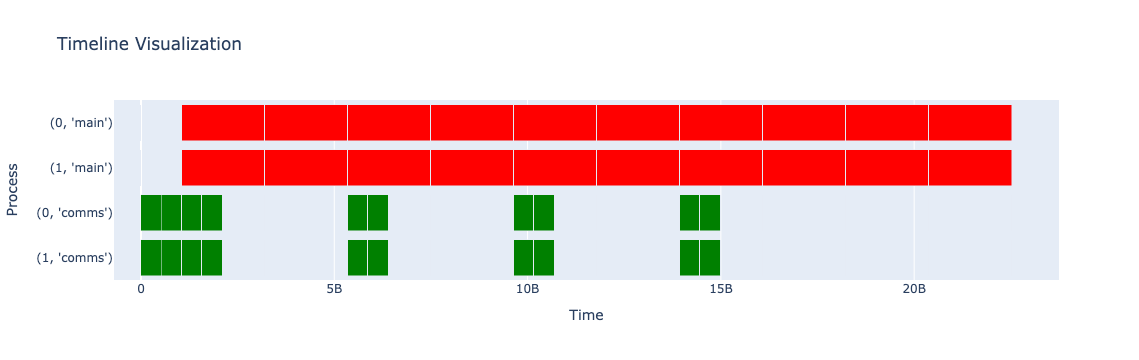

In [26]:
from controller.simulator import simulate_commands, chrome_events, visualize_events, analyze_events
events = simulate_commands(device_mesh.ctrl.backend.worker_commands)
# print(device_mesh.ctrl.backend.worker_commands)
visualize_events(events)
# analyze_events(events)

In [ ]:
[i.outputs for i in device_mesh.ctrl.backend.worker_commands[(1, 'comms')]]

In [65]:
bw_call(out)

(OrderedDict([('w1.weight',
               DTensor(mesh=<DeviceMesh(('host', 'gpu'), [1, 4]) at 0x7f80e8cfd010>, stream=stream 'main', fake=FakeTensor(..., device='cuda:0', size=(1024, 1024)))),
              ('w1.bias',
               DTensor(mesh=<DeviceMesh(('host', 'gpu'), [1, 4]) at 0x7f80e8cfd010>, stream=stream 'main', fake=FakeTensor(..., device='cuda:0', size=(1024,)))),
              ('w2.weight',
               DTensor(mesh=<DeviceMesh(('host', 'gpu'), [1, 4]) at 0x7f80e8cfd010>, stream=stream 'main', fake=FakeTensor(..., device='cuda:0', size=(1024, 1024)))),
              ('w2.bias',
               DTensor(mesh=<DeviceMesh(('host', 'gpu'), [1, 4]) at 0x7f80e8cfd010>, stream=stream 'main', fake=FakeTensor(..., device='cuda:0', size=(1024,))))]),
 DTensor(mesh=<DeviceMesh(('host', 'gpu'), [1, 4]) at 0x7f80e8cfd010>, stream=stream 'main', fake=FakeTensor(..., device='cuda:0', size=(1024, 1024))))

In [ ]:
mlp(x).sum().backward()